# 01 · EDA — AWARE Prioritisation Challenge

**Pregunta:** en cada snapshot (cada 3 s) AWARE lista ~36 tareas abiertas; ¿en cuál está trabajando el controlador? Entregamos 3 `row_index` por muestra y la métrica es *top-3 hit rate*.

Este notebook busca entender los datos a fondo antes de modelar:

1. Estructura del dataset (sesiones, controladores, escenarios, tamaño de las listas)
2. La etiqueta: qué tipos de tarea se eligen y cuánto «sobre-representan» respecto a su presencia
3. Variabilidad entre controladores y escenarios
4. Valores vacíos: qué significan
5. Qué separa a la tarea elegida de las demás (dentro de la misma muestra y del mismo tipo)
6. Poder univariante de cada feature como *ranker* y correlaciones
7. Estructura temporal: episodios, persistencia de la etiqueta
8. Inputs del controlador: pasado vs futuro (la feature clave del baseline)
9. Alineamiento entre controladores del mismo escenario
10. Ablación rápida del baseline LightGBM
11. Conclusiones y posibles enfoques

> Convención: «muestra» = un snapshot (`sample_id`); «fila» = una tarea del snapshot.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib as mpl
import seaborn as sns
from pathlib import Path
import warnings; warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "Data"

TYPES = ['entry_conflict_resolution', 'exit_conflict_resolution', 'entry_coordination', 'exit_coordination',
         'assume_aircraft', 'transfer_aircraft', 'conflict_resolution', 'non_conformance_resolution',
         'qos_improvement', 'entry_conditions', 'exit_conditions', 'aircraft_request', 'zone_conflict',
         'return_to_route']

# Paleta categórica validada (orden fijo) + neutros
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100", magenta="#e87ba4",
         green="#008300", violet="#6250d6", red="#e34948", ink="#0b0b0b", ink2="#52514e", grid="#e4e3df")
TARGET, OTHER = C["orange"], C["blue"]   # elegida vs resto, en todo el notebook

mpl.rcParams.update({
    "figure.dpi": 110, "figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": C["ink2"], "axes.labelcolor": C["ink2"], "xtick.color": C["ink2"], "ytick.color": C["ink2"],
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 11, "axes.titlelocation": "left", "legend.frameon": False,
    "font.size": 9.5, "lines.linewidth": 2,
})
pd.set_option("display.max_columns", 60, "display.width", 160)

In [2]:
tr = pd.read_csv(DATA / "train.csv").assign(split="train")
va = pd.read_csv(DATA / "validation.csv").assign(split="validation")
te = pd.read_csv(DATA / "test.csv").assign(split="test", target_index=np.nan)
d = pd.concat([tr, va, te], ignore_index=True)

d["type"] = d.task_index.map(dict(enumerate(TYPES)))
d["cs"] = [n[len(TYPES[t]) + 1:].split("_")[0] for n, t in zip(d.task_name, d.task_index)]   # avión de la tarea
d["t"] = pd.to_timedelta(d.timestamp).dt.total_seconds()
d["t_scn"] = d.t - d.groupby("session").t.transform("min")                                  # s desde el 1er snapshot
d = d.sort_values(["session", "t", "row_index"]).reset_index(drop=True)

lab = d[d.split != "test"]                       # filas etiquetadas
pos = lab[lab.target_index == 1].copy()          # una fila por muestra: la respuesta
print(d.groupby("split").agg(muestras=("sample_id", "nunique"), filas=("sample_id", "size"),
                             sesiones=("session", "nunique"), atcos=("atco", "nunique")))

            muestras   filas  sesiones  atcos
split                                        
test            1863   66409         5      2
train          11923  432578        34     16
validation      1252   42110         3      2


## 1 · Estructura del dataset

Cada sesión = controlador × escenario. Los 3 escenarios tienen el mismo tráfico en todas las sesiones. Test son los controladores 020 (leaderboard público) y 023 (privado, el que decide).

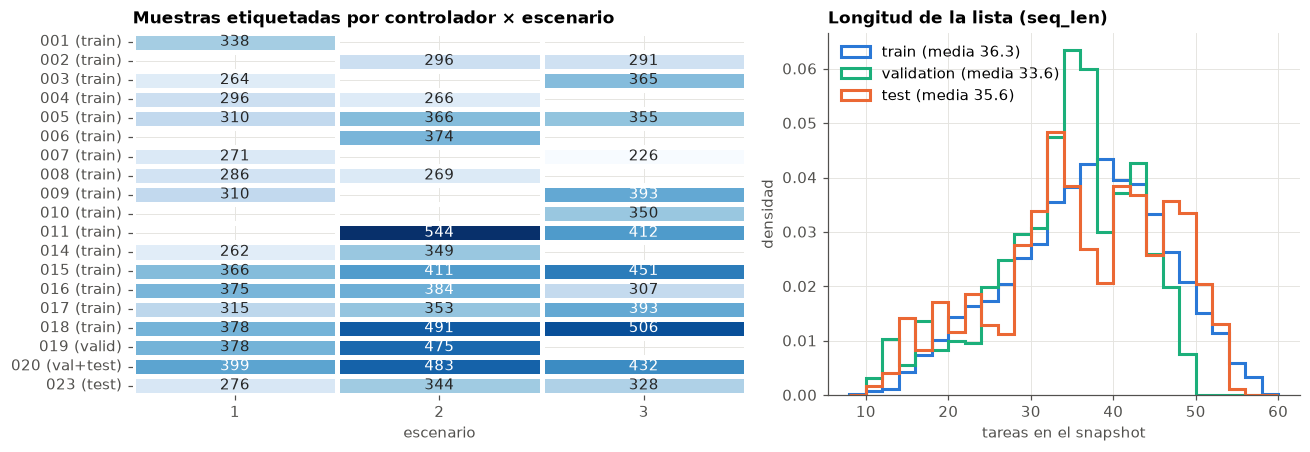

In [3]:
ses = d.groupby(["session", "split"]).agg(atco=("atco", "first"), scenario=("scenario", "first"),
        muestras=("sample_id", "nunique"), dur_min=("t", lambda s: (s.max() - s.min()) / 60),
        seq_len=("seq_len", "mean")).reset_index()

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw=dict(width_ratios=[1.3, 1]))
piv = ses.pivot_table(index="atco", columns="scenario", values="muestras")
spl = ses.drop_duplicates("atco").set_index("atco").split
sns.heatmap(piv, annot=True, fmt=".0f", cmap="Blues", cbar=False, ax=ax[0], linewidths=2, linecolor="white")
ax[0].set_yticklabels([f"{int(a):03d} ({spl[int(a)][:5]})" if a != 20 else "020 (val+test)" for a in piv.index], rotation=0)
ax[0].set(title="Muestras etiquetadas por controlador × escenario", xlabel="escenario", ylabel="")

spl_s = d.drop_duplicates("sample_id")
for s, c in zip(["train", "validation", "test"], [C["blue"], C["aqua"], C["orange"]]):
    x = spl_s[spl_s.split == s].seq_len
    ax[1].hist(x, bins=np.arange(8, 61, 2), density=True, histtype="step", lw=2, color=c, label=f"{s} (media {x.mean():.1f})")
ax[1].set(title="Longitud de la lista (seq_len)", xlabel="tareas en el snapshot", ylabel="densidad"); ax[1].legend()
plt.tight_layout()

**Lectura:** ~350 muestras por sesión de ~1 h, pero solo hay muestra cuando el controlador estaba haciendo algo etiquetado (no es un muestreo continuo). Elegir 3 de ~36 al azar ≈ 9 % → ese es el suelo.

## 2 · La etiqueta: qué tipos se eligen

Comparamos la proporción de **filas** de cada tipo con la proporción de **respuestas**. El cociente es el *lift*: >1 = el controlador lo elige más de lo que aparece.

,% filas,% respuestas,lift,P(elegida | presente),% muestras con el tipo
type,,,,,
transfer_aircraft,6.4%,26.8%,4.20,11.7%,90.0%
assume_aircraft,16.6%,25.5%,1.54,4.3%,98.3%
zone_conflict,11.2%,16.1%,1.44,4.0%,99.1%
entry_coordination,29.8%,8.1%,0.27,0.8%,98.1%
return_to_route,3.5%,7.1%,2.04,5.7%,72.3%
exit_coordination,12.7%,5.7%,0.45,1.2%,99.6%
exit_conditions,7.7%,3.4%,0.44,1.2%,93.4%
conflict_resolution,2.3%,3.0%,1.27,3.5%,33.5%
qos_improvement,6.3%,2.0%,0.31,0.9%,86.7%


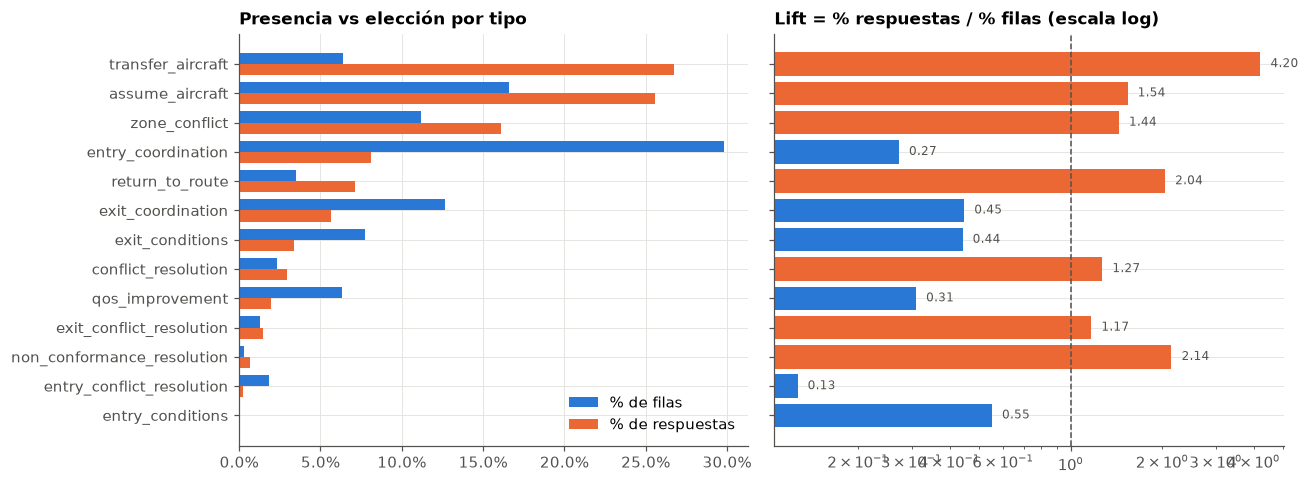

In [4]:
rows = lab.type.value_counts(normalize=True).rename("% filas")
ans = pos.type.value_counts(normalize=True).rename("% respuestas")
tt = pd.concat([rows, ans], axis=1).fillna(0)
tt["lift"] = tt["% respuestas"] / tt["% filas"]
tt["P(elegida | presente)"] = lab.groupby("type").target_index.mean()
# en qué % de muestras aparece al menos una tarea de ese tipo
tt["% muestras con el tipo"] = lab.groupby("type").sample_id.nunique() / lab.sample_id.nunique()
tt = tt.sort_values("% respuestas", ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
y = np.arange(len(tt)); h = 0.38
ax[0].barh(y - h/2, tt["% filas"], h, color=OTHER, label="% de filas")
ax[0].barh(y + h/2, tt["% respuestas"], h, color=TARGET, label="% de respuestas")
ax[0].set_yticks(y, tt.index); ax[0].invert_yaxis(); ax[0].legend(loc="lower right")
ax[0].xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1)); ax[0].set_title("Presencia vs elección por tipo")
ax[1].barh(y, tt.lift, color=[TARGET if v > 1 else OTHER for v in tt.lift])
ax[1].axvline(1, color=C["ink2"], lw=1, ls="--"); ax[1].set_xscale("log")
ax[1].set_title("Lift = % respuestas / % filas (escala log)")
for yi, v in zip(y, tt.lift): ax[1].text(v * 1.08, yi, f"{v:.2f}", va="center", fontsize=8, color=C["ink2"])
plt.tight_layout()
tt.style.format({c: "{:.1%}" for c in tt.columns if c != "lift"} | {"lift": "{:.2f}"})

**Lectura:**
- `transfer_aircraft` y `assume_aircraft` son la mitad de las respuestas. `zone_conflict` y `return_to_route` también sobre-representan.
- `entry_coordination` es el 30 % de las filas pero solo el 8 % de respuestas: casi siempre convive con un `assume_aircraft` del mismo avión (caso «twin»).
- `aircraft_request` (11) no aparece; `entry_conditions` (9) es residual.
- Un prior por tipo ya da ~0.31 de top-3 en etiquetado → el resto tiene que salir de **qué avión**.

In [5]:
# Caso twin: avión con assume + entry_coordination a la vez
tw = pos[pos.l_twin_AE == 1]
print(f"Muestras cuya respuesta es un twin: {len(tw)/len(pos):.1%}")
print(tw.type.value_counts(normalize=True).round(3).to_string())

Muestras cuya respuesta es un twin: 29.9%
type
assume_aircraft              0.730
entry_coordination           0.267
entry_conflict_resolution    0.003


## 3 · Variabilidad entre controladores y escenarios

¿Todos los controladores reparten su atención igual? Si hay mucho estilo personal, un modelo debe ser robusto (los de test no se han visto).

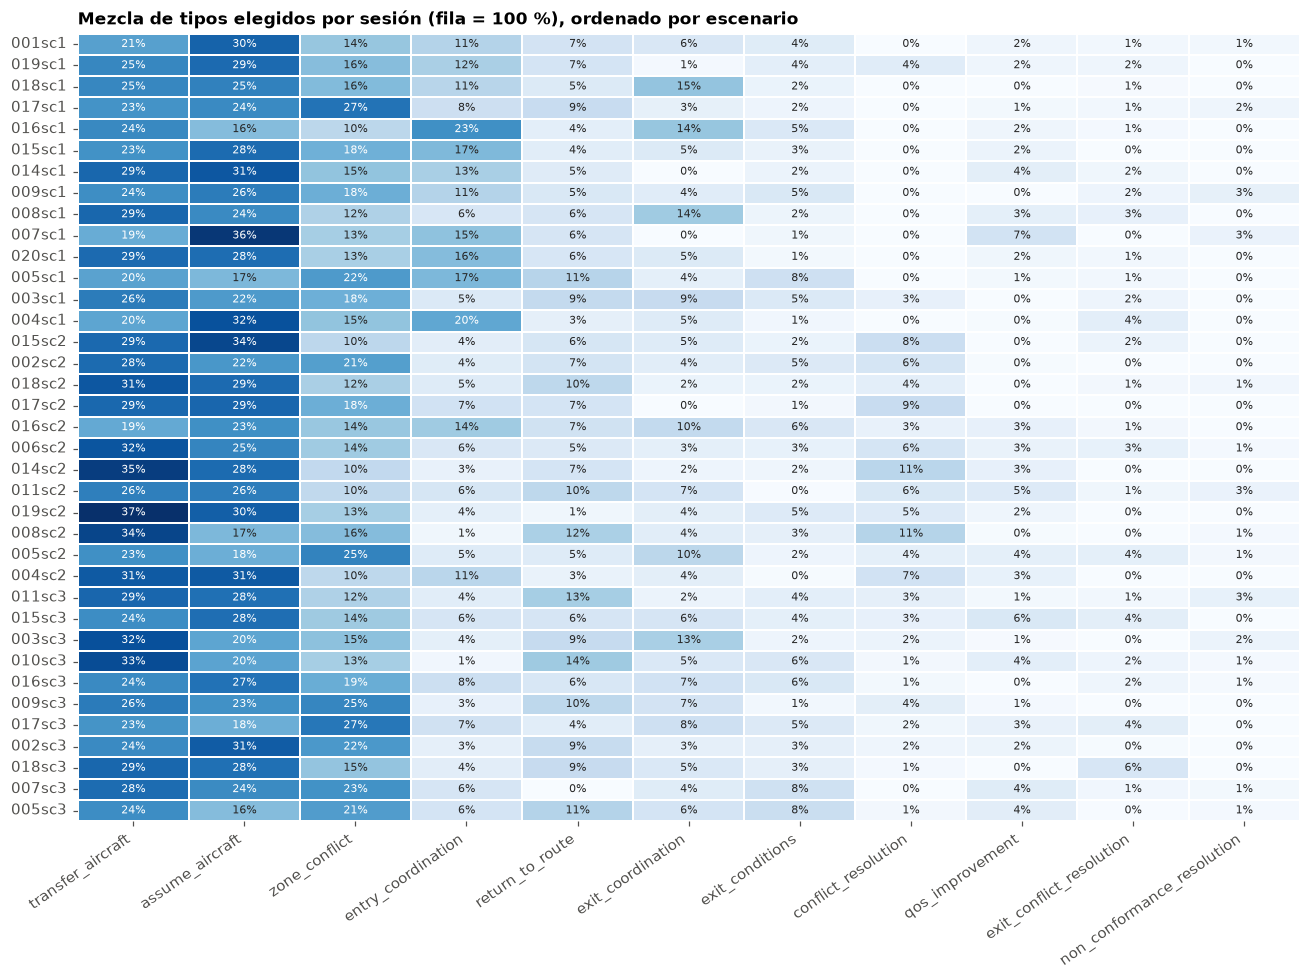

In [6]:
mix = pd.crosstab(pos.session, pos.type, normalize="index")
mix = mix[tt.index[tt["% respuestas"] > 0.005]]
mix["scn"] = mix.index.str[-1]; mix = mix.sort_values(["scn"]).drop(columns="scn")
fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(mix, cmap="Blues", annot=True, fmt=".0%", annot_kws=dict(size=7), cbar=False, linewidths=1, linecolor="white", ax=ax)
ax.set(title="Mezcla de tipos elegidos por sesión (fila = 100 %), ordenado por escenario", xlabel="", ylabel="")
plt.setp(ax.get_xticklabels(), rotation=35, ha="right"); plt.tight_layout()

In [7]:
# Mismo análisis agregado por escenario y por controlador: ¿qué varía más?
from scipy.stats import chi2_contingency
for g in ["scenario", "atco"]:
    ct = pd.crosstab(pos[g], pos.type)
    chi2, p, dof, _ = chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    print(f"Cramér's V tipo ~ {g:8s}: {v:.3f}")
pd.crosstab(pos.scenario, pos.type, normalize="index")[mix.columns].style.format("{:.0%}").background_gradient("Blues", axis=None)

Cramér's V tipo ~ scenario: 0.159
Cramér's V tipo ~ atco    : 0.096


type,transfer_aircraft,assume_aircraft,zone_conflict,entry_coordination,return_to_route,exit_coordination,exit_conditions,conflict_resolution,qos_improvement,exit_conflict_resolution,non_conformance_resolution
scenario,,,,,,,,,,,
1,24%,26%,16%,13%,6%,6%,3%,1%,2%,1%,1%
2,29%,26%,14%,6%,7%,5%,3%,6%,2%,1%,1%
3,27%,24%,18%,5%,9%,6%,4%,2%,2%,2%,1%


**Lectura:** la mezcla de tipos depende más del **escenario** (Cramér's V ≈ 0.16: el tráfico y las zonas militares activas cambian qué tareas existen, p. ej. el peso de `zone_conflict`) que del **controlador** (≈ 0.10). Aun así, dentro de un mismo escenario las sesiones difieren visiblemente → el prior por tipo debe ser condicional al contexto (qué tareas hay en la lista), no fijo.

## 4 · Valores vacíos

Los vacíos significan «no aplica». La pregunta útil: ¿de qué dependen? Si dependen de `is_assumed`, la propia presencia de NaN es información (y LightGBM la aprovecha de forma nativa).

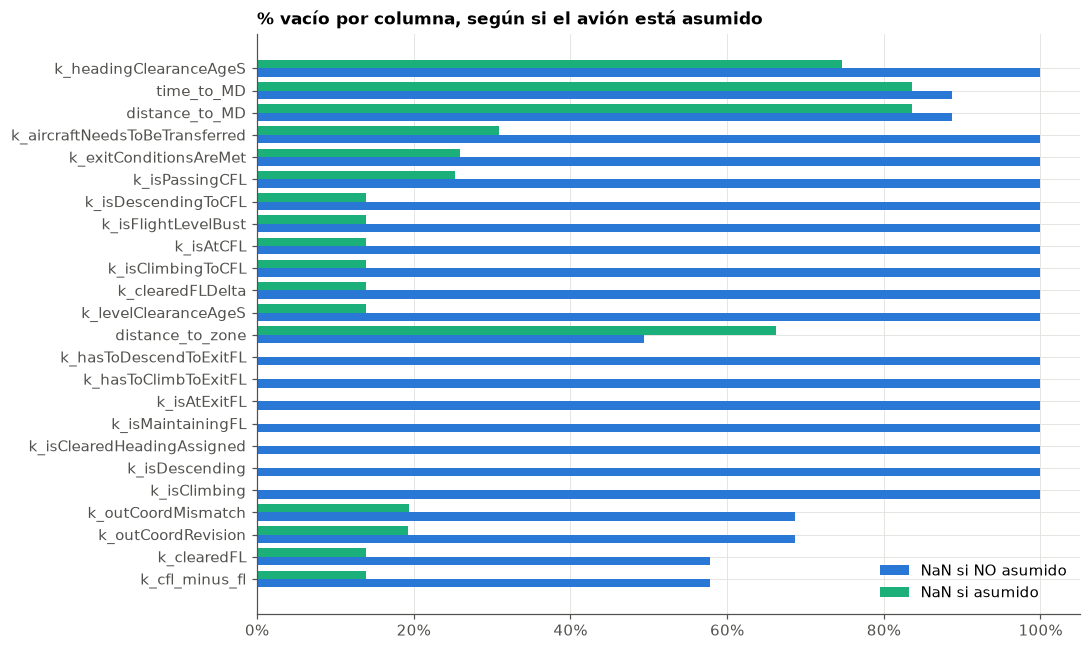

In [8]:
na = lab.isna().mean()
na = na[na > 0.01].sort_values()
by_ass = lab.groupby("is_assumed")[na.index].apply(lambda g: g.isna().mean()).T
by_ass.columns = ["NaN si NO asumido", "NaN si asumido"]
fig, ax = plt.subplots(figsize=(10, 6))
y = np.arange(len(by_ass)); h = 0.38
ax.barh(y - h/2, by_ass.iloc[:, 0], h, color=OTHER, label=by_ass.columns[0])
ax.barh(y + h/2, by_ass.iloc[:, 1], h, color=C["aqua"], label=by_ass.columns[1])
ax.set_yticks(y, by_ass.index); ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1))
ax.set_title("% vacío por columna, según si el avión está asumido"); ax.legend(loc="lower right"); plt.tight_layout()

**Lectura:** los `k_*` están vacíos casi siempre que el avión no está asumido; `distance_to_MD/time_to_MD` solo existen con conflicto, `distance_to_zone` solo si la ruta cruza zona. **No imputar con 0**: o se deja NaN (árboles) o se añade un indicador.

## 5 · ¿Qué distingue a la tarea elegida?

Comparar la elegida con «todas las demás» mezcla tipos; por eso miramos también **dentro del mismo tipo**. Primero, la feature más intuitiva: tiempo al borde del sector (negativo = dentro).

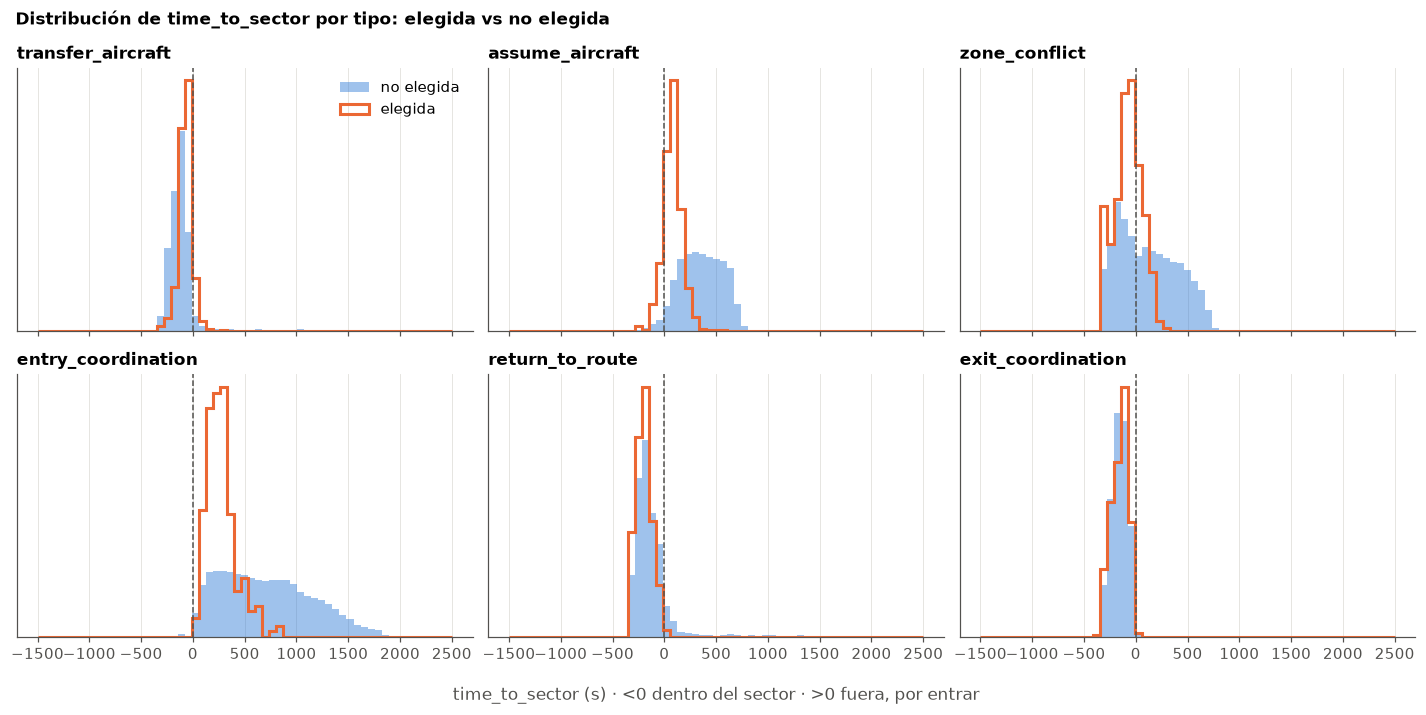

In [9]:
top_types = ["transfer_aircraft", "assume_aircraft", "zone_conflict", "entry_coordination", "return_to_route", "exit_coordination"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharex=True)
bins = np.linspace(-1500, 2500, 60)
for ax, ty in zip(axes.flat, top_types):
    g = lab[lab.type == ty]
    ax.hist(g[g.target_index == 0].time_to_sector, bins, density=True, color=OTHER, alpha=0.45, label="no elegida")
    ax.hist(g[g.target_index == 1].time_to_sector, bins, density=True, histtype="step", color=TARGET, lw=2, label="elegida")
    ax.axvline(0, color=C["ink2"], lw=1, ls="--"); ax.set_title(ty); ax.set_yticks([])
axes[0, 0].legend(); fig.supxlabel("time_to_sector (s) · <0 dentro del sector · >0 fuera, por entrar", color=C["ink2"])
fig.suptitle("Distribución de time_to_sector por tipo: elegida vs no elegida", x=0.01, ha="left", weight="bold")
plt.tight_layout()

**Lectura:** el momento de cada tarea encaja con el flujo del avión: `assume` se atiende **justo antes de entrar** (time_to_sector pequeño y positivo), `transfer` **justo antes de salir** (negativo pequeño). Las no elegidas están mucho más dispersas. Esto es lo que explota el `sample_submission` (tipo + cercanía al borde, 0.352 en test); una versión suavizada (log-prior del tipo − |time_to_sector|/300) llega a ~0.50 en train+val (sección 6).

Siguiente pregunta: entre las tareas del **mismo tipo** en una muestra, ¿cuál se elige? Usamos los rangos `l_rank_*_type` (1 = el más extremo).

transfer_aircraft    P(elegida es rango 1 en |t_sector| de su tipo) = 0.72   (n medio del tipo = 2.9)
assume_aircraft      P(elegida es rango 1 en |t_sector| de su tipo) = 0.68   (n medio del tipo = 6.7)
zone_conflict        P(elegida es rango 1 en |t_sector| de su tipo) = 0.50   (n medio del tipo = 4.5)


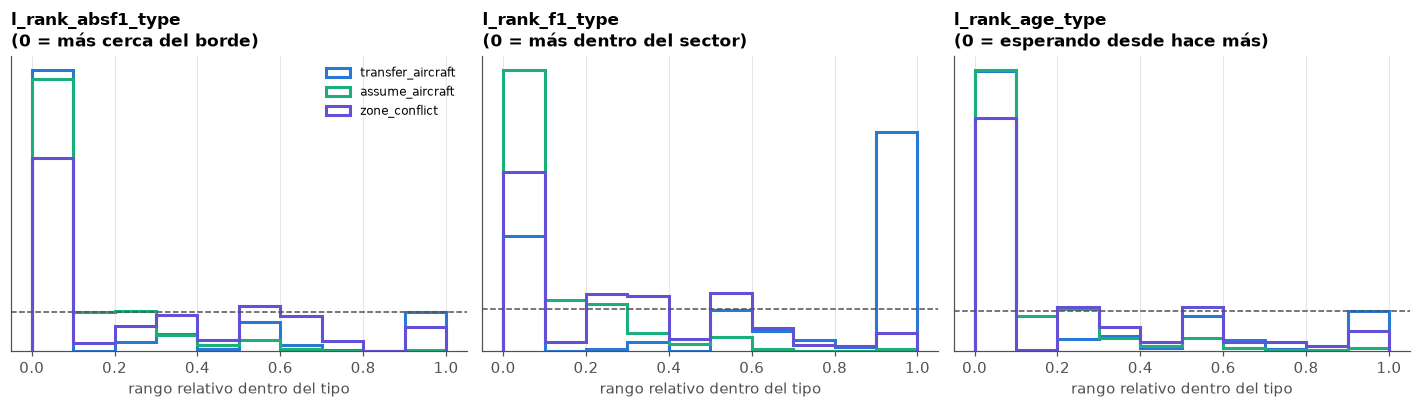

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, col, ttl in zip(axes, ["l_rank_absf1_type", "l_rank_f1_type", "l_rank_age_type"],
                        ["más cerca del borde", "más dentro del sector", "esperando desde hace más"]):
    for ty, c in zip(["transfer_aircraft", "assume_aircraft", "zone_conflict"], [C["blue"], C["aqua"], C["violet"]]):
        g = pos[pos.type == ty]
        # normalizamos por cuántas hay de ese tipo: rango relativo 0..1, y lo comparamos con uniforme
        r = ((g[col] - 1) / (g.l_n_type - 1).clip(lower=1)).clip(0, 1)
        ax.hist(r, bins=np.linspace(0, 1, 11), density=True, histtype="step", lw=2, color=c, label=ty)
    ax.axhline(1, color=C["ink2"], ls="--", lw=1)
    ax.set(title=f"{col}\n(0 = {ttl})", xlabel="rango relativo dentro del tipo", yticks=[])
axes[0].legend(fontsize=8); plt.tight_layout()
for ty in ["transfer_aircraft", "assume_aircraft", "zone_conflict"]:
    g = pos[pos.type == ty]
    print(f"{ty:20s} P(elegida es rango 1 en |t_sector| de su tipo) = {(g.l_rank_absf1_type == 1).mean():.2f}"
          f"   (n medio del tipo = {g.l_n_type.mean():.1f})")

**Lectura:** la línea discontinua es «al azar». Para `transfer` y `assume` la elegida suele ser la más próxima al borde → estrategia FIFO espacial. Pero lejos de ser determinista: hay mucha masa en otros rangos (estilo del controlador + ruido de etiquetado).

Ahora una vista general: diferencia de medias (estandarizada) entre elegida y resto **dentro de cada muestra**, para todas las numéricas.

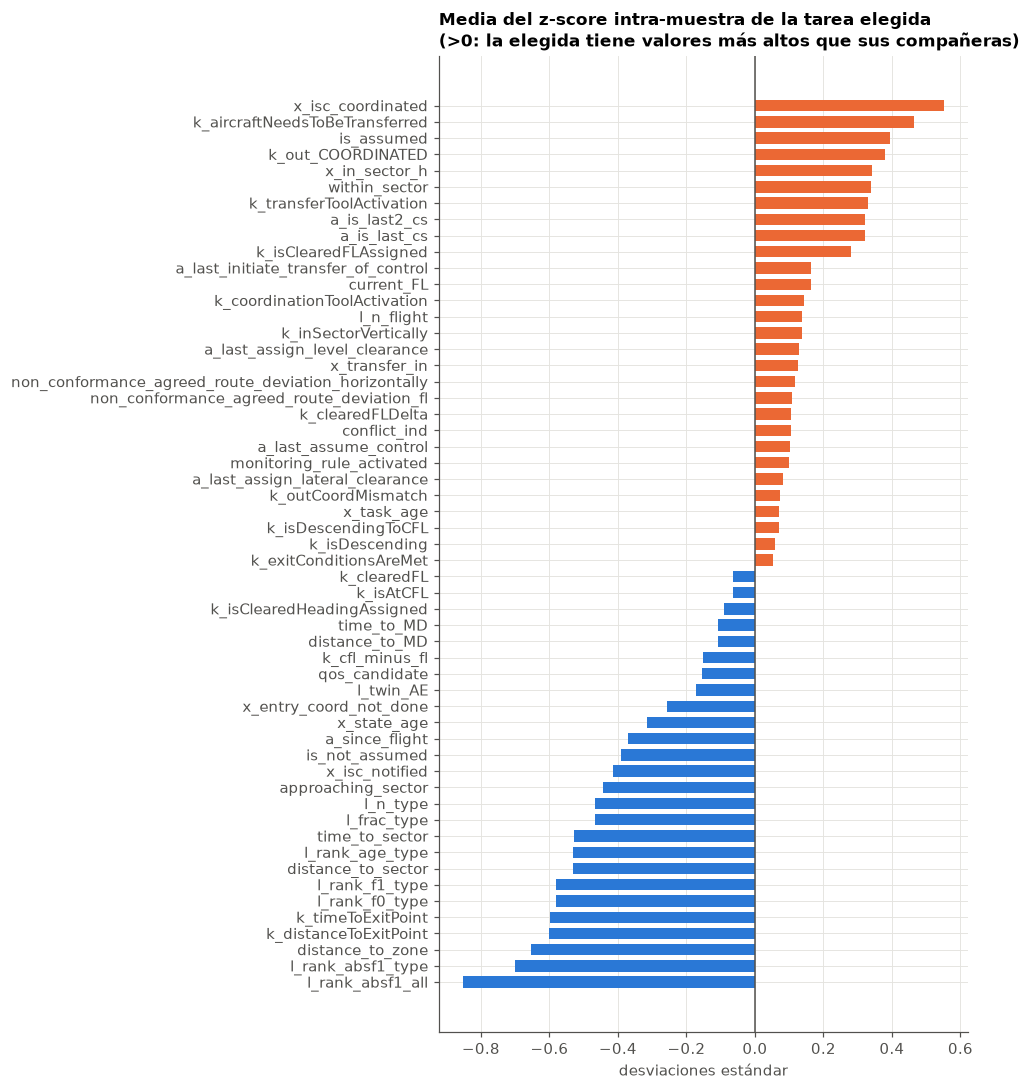

In [11]:
num = [c for c in lab.columns if lab[c].dtype.kind in "fi" and c not in
       ("sample_id", "target_index", "row_index", "task_index", "atco", "scenario", "t", "t_scn")]
# z-score dentro de cada muestra -> elimina diferencias entre snapshots
z = lab[num].groupby(lab.sample_id).transform(lambda x: (x - x.mean()) / (x.std() + 1e-9))
eff = z[lab.target_index == 1].mean().sort_values()
eff = eff[eff.abs() > 0.05]
fig, ax = plt.subplots(figsize=(9, 10))
ax.barh(eff.index, eff.values, color=[TARGET if v > 0 else OTHER for v in eff.values], height=0.7)
ax.axvline(0, color=C["ink2"], lw=1)
ax.set(title="Media del z-score intra-muestra de la tarea elegida\n(>0: la elegida tiene valores más altos que sus compañeras)",
       xlabel="desviaciones estándar"); plt.tight_layout()

## 6 · Poder de cada feature como ranker (univariante) y correlaciones

Para cada feature ordenamos las tareas de cada muestra por ella (en el sentido que mejor funcione, NaN al final) y calculamos el top-3 hit rate. Es una medida directa y en la métrica del reto.

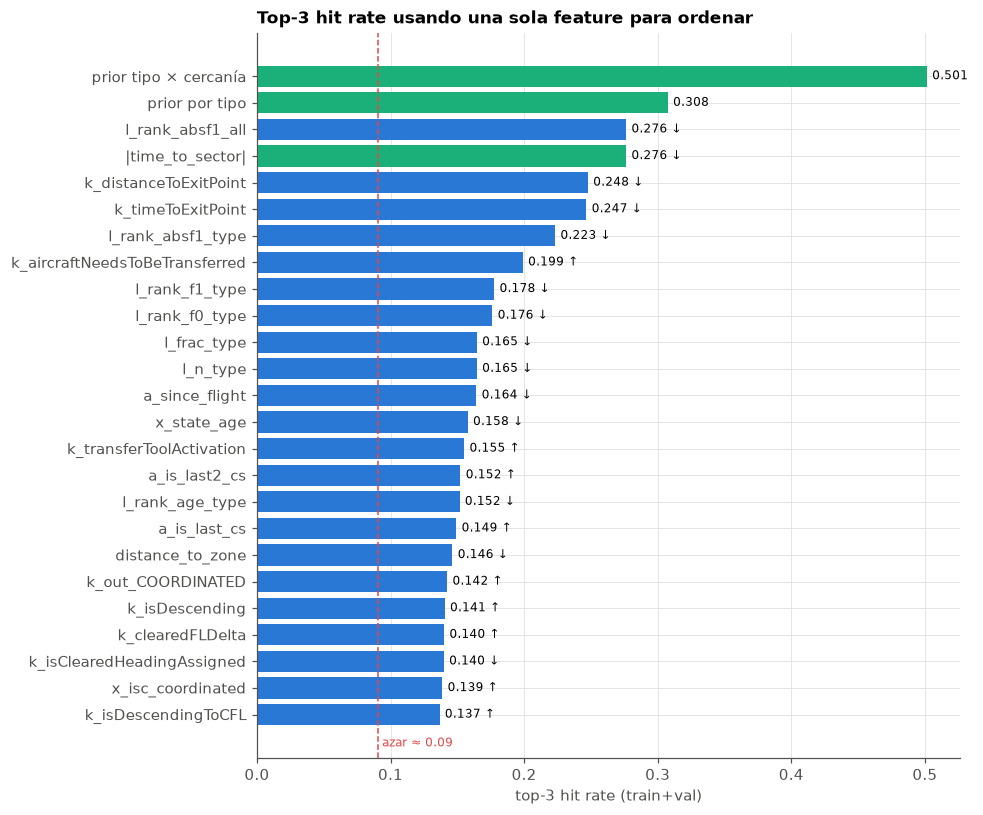

In [12]:
def hit3(df, score):
    # top-3 hit rate ordenando por score descendente dentro de cada sample_id (NaN al final)
    r = pd.Series(score, index=df.index).fillna(-np.inf).groupby(df.sample_id.values).rank(ascending=False, method="first")
    return float((r[df.target_index == 1] <= 3).mean())

res = []
for c in num:
    x = lab[c].astype(float)
    res.append((c, hit3(lab, x), hit3(lab, -x)))
uni = pd.DataFrame(res, columns=["feature", "alto primero", "bajo primero"]).set_index("feature")
uni["mejor"] = uni.max(axis=1); uni["sentido"] = np.where(uni["alto primero"] >= uni["bajo primero"], "↑", "↓")
prior = pos.task_index.value_counts(normalize=True)
uni.loc["prior por tipo", ["mejor", "sentido"]] = hit3(lab, lab.task_index.map(prior).fillna(0)), ""
uni.loc["|time_to_sector|", ["mejor", "sentido"]] = hit3(lab, -lab.time_to_sector.abs()), "↓"
uni.loc["prior tipo × cercanía", ["mejor", "sentido"]] = hit3(lab, np.log(lab.task_index.map(prior).fillna(1e-4)) - lab.time_to_sector.abs() / 300), ""
top = uni.sort_values("mejor", ascending=False).head(25)

fig, ax = plt.subplots(figsize=(9, 7.5))
ax.barh(top.index[::-1], top.mejor[::-1], color=[C["aqua"] if i in ("prior por tipo", "|time_to_sector|", "prior tipo × cercanía") else OTHER for i in top.index[::-1]])
rnd = (3 / lab.drop_duplicates("sample_id").seq_len).mean()
ax.axvline(rnd, color=C["red"], ls="--", lw=1); ax.text(rnd, -1.2, f" azar ≈ {rnd:.2f}", color=C["red"], fontsize=8)
for i, (v, s) in enumerate(zip(top.mejor[::-1], top.sentido[::-1])): ax.text(v + 0.004, i, f"{v:.3f} {s}", va="center", fontsize=8)
ax.set(title="Top-3 hit rate usando una sola feature para ordenar", xlabel="top-3 hit rate (train+val)"); plt.tight_layout()

Text(0.5, 1.0, 'Correlación de Spearman entre features (clustering jerárquico)')

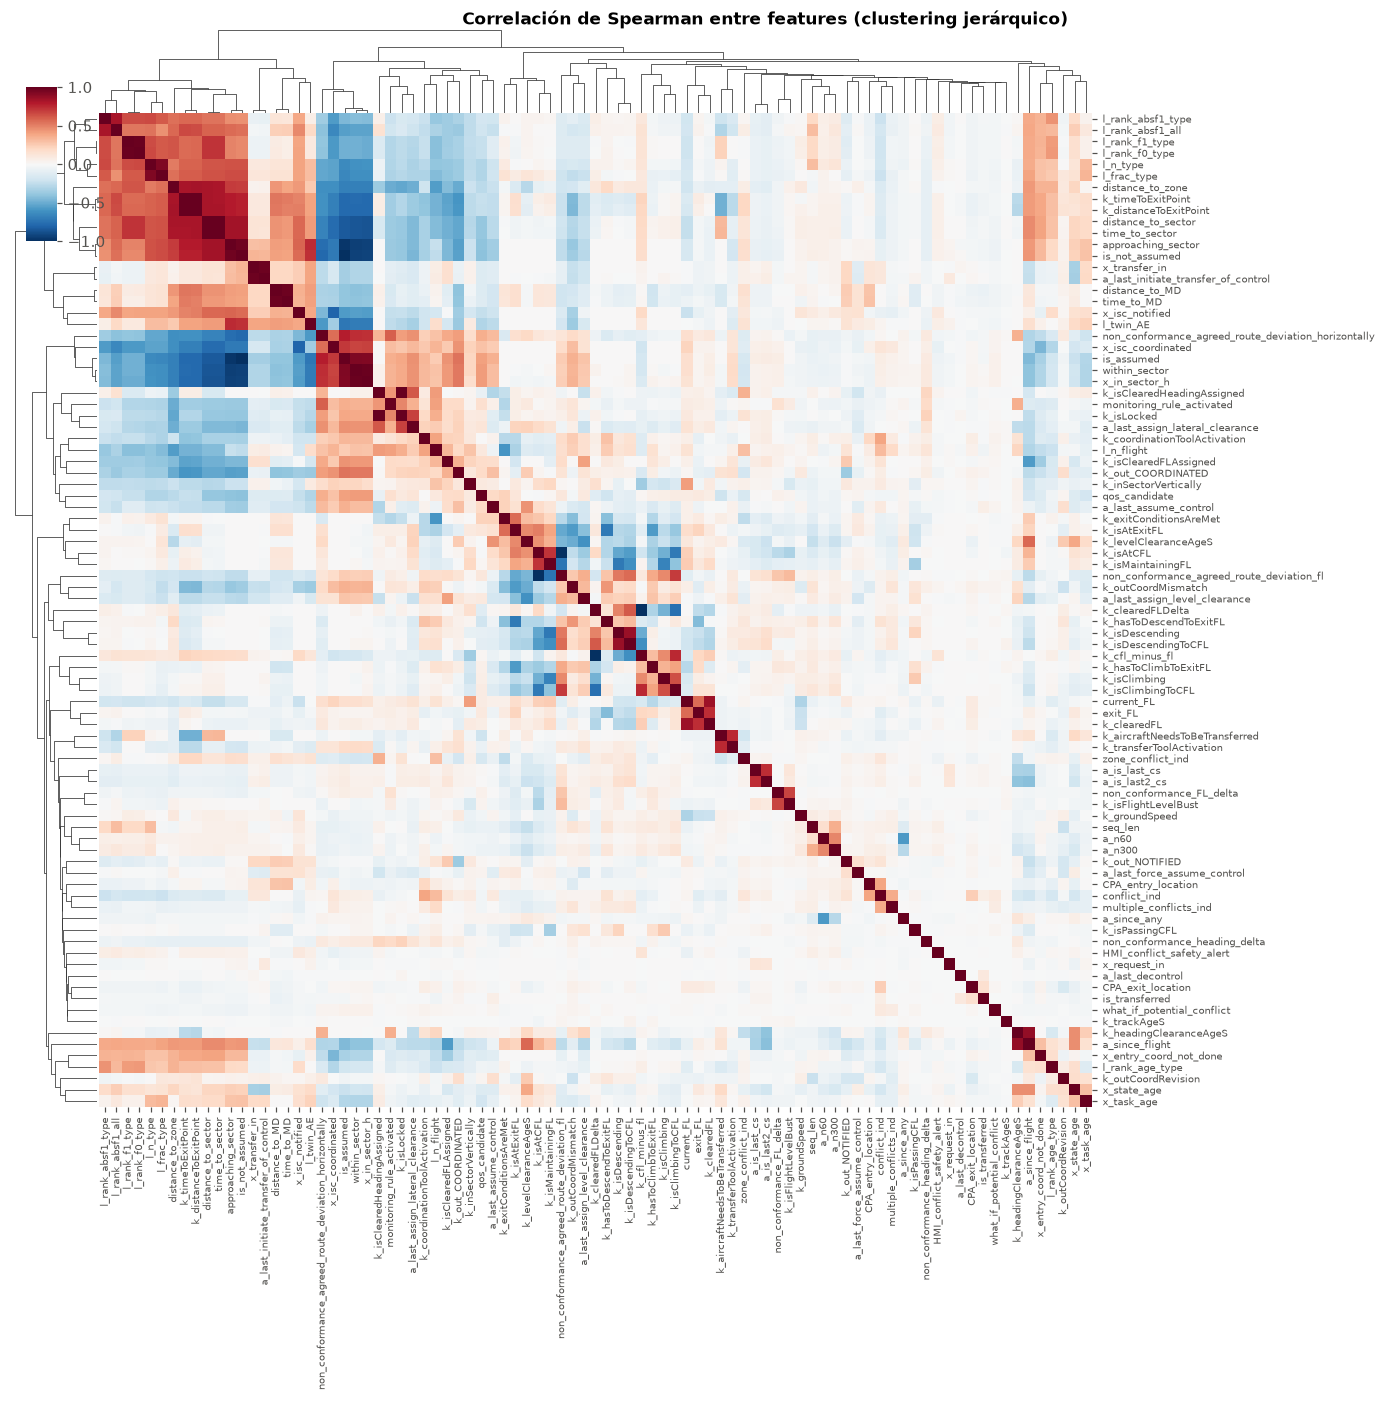

In [13]:
# Correlación entre features (Spearman sobre una muestra de filas), agrupada jerárquicamente
sub = lab[num].sample(60000, random_state=0)
keep = [c for c in num if sub[c].nunique() > 1 and sub[c].notna().mean() > 0.1]
corr = sub[keep].corr("spearman").fillna(0)
cg = sns.clustermap(corr, cmap="RdBu_r", vmin=-1, vmax=1, figsize=(14, 14), xticklabels=True, yticklabels=True,
                    cbar_pos=(0.02, 0.85, 0.02, 0.1), dendrogram_ratio=0.08)
cg.ax_heatmap.tick_params(labelsize=6.5); cg.fig.suptitle("Correlación de Spearman entre features (clustering jerárquico)", x=0.5, y=1.0, weight="bold")

In [14]:
# Pares casi redundantes (|rho| > 0.95): candidatos a eliminar
pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack()
pairs[pairs.abs() > 0.95].sort_values(key=abs, ascending=False).round(3).to_frame("rho")

,,rho
k_clearedFLDelta,k_cfl_minus_fl,-1.000
k_isClearedHeadingAssigned,k_isLocked,1.000
distance_to_sector,time_to_sector,0.999
is_assumed,is_not_assumed,-0.998
non_conformance_agreed_route_deviation_fl,k_isAtCFL,-0.997
k_timeToExitPoint,k_distanceToExitPoint,0.996
within_sector,x_in_sector_h,0.988
l_rank_f1_type,l_rank_f0_type,0.986
x_transfer_in,a_last_initiate_transfer_of_control,0.984
distance_to_MD,time_to_MD,0.982


**Lectura:** hay bloques muy redundantes (distancia ↔ tiempo al sector, `within_sector` ↔ `x_in_sector_h`, `is_assumed` ↔ `is_not_assumed`, familias `k_` de nivel). Para árboles no es grave; para modelos lineales/NN conviene podar. Ninguna feature aislada supera claramente al prior por tipo combinado con cercanía al borde.

## 7 · Estructura temporal: episodios

Las muestras están a 3 s y la etiqueta persiste. Definimos un **episodio** como una racha de muestras consecutivas (hueco ≤ 4.5 s, hay snapshots a 3 y 4 s) con la misma tarea etiquetada.

Muestras contiguas a la anterior (hueco ≤ 4.5 s):           76.3%
De ellas, misma tarea que la anterior:                    94.8%
... mismo avión que la anterior:                          95.7%
Episodios: 3655  · mediana 3 muestras · media 3.6


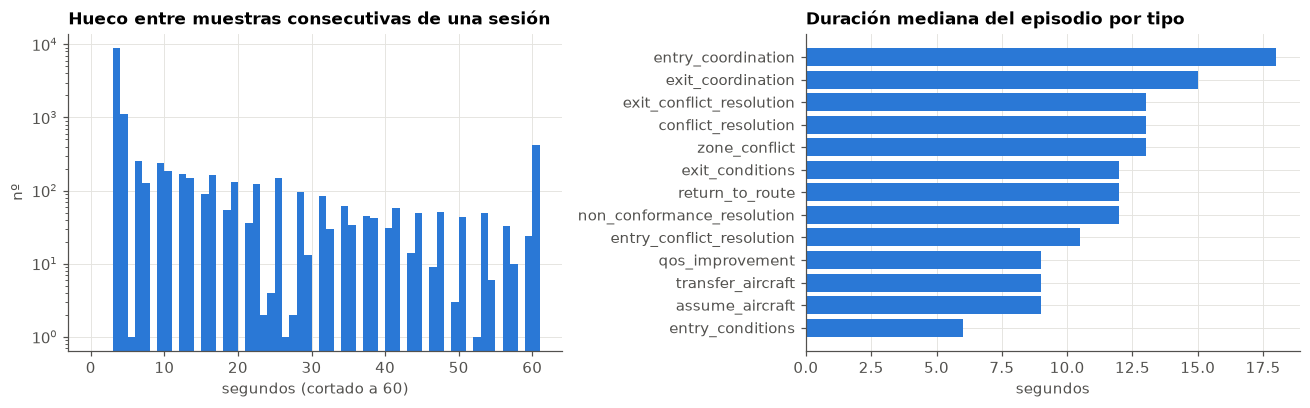

In [15]:
pos = pos.sort_values(["session", "t"])
gap = pos.groupby("session").t.diff()
same = (pos.task_name == pos.groupby("session").task_name.shift()) & (gap <= 4.5)
same_ac = (pos.cs == pos.groupby("session").cs.shift()) & (gap <= 4.5)
pos["episode"] = (~same).cumsum()
ep = pos.groupby("episode").agg(n=("t", "size"), dur=("t", lambda s: s.max() - s.min() + 3), type=("type", "first"))
print(f"Muestras contiguas a la anterior (hueco ≤ 4.5 s):           {(gap <= 4.5).mean():.1%}")
print(f"De ellas, misma tarea que la anterior:                    {same[gap <= 4.5].mean():.1%}")
print(f"... mismo avión que la anterior:                          {same_ac[gap <= 4.5].mean():.1%}")
print(f"Episodios: {len(ep)}  · mediana {ep.n.median():.0f} muestras · media {ep.n.mean():.1f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].hist(gap.dropna().clip(upper=60), bins=np.arange(0, 62, 1), color=OTHER)
ax[0].set(title="Hueco entre muestras consecutivas de una sesión", xlabel="segundos (cortado a 60)", ylabel="nº", yscale="log")
o = ep.groupby("type").dur.median().sort_values()
ax[1].barh(o.index, o.values, color=OTHER); ax[1].set(title="Duración mediana del episodio por tipo", xlabel="segundos")
plt.tight_layout()

**Lectura:** cuando dos muestras son contiguas (3–4 s), la tarea se repite ~95 % de las veces; los episodios se cortan sobre todo por **huecos** (momentos sin etiqueta). Implicaciones:
- **Validación**: siempre por sesión/controlador.
- **Suavizado temporal en test**: las predicciones de muestras contiguas se pueden promediar/forzar a ser coherentes — post-proceso tipo ventana/HMM. Es una ganancia casi gratis.
- Los huecos también son información: el inicio de un bloque contiguo de muestras ≈ inicio de una nueva tarea.
- El número efectivo de ejemplos independientes es ~4.7k episodios, no 13k muestras → modelos pequeños/regularizados.

Línea temporal de una sesión: en el eje Y cada avión, en naranja la tarea etiquetada, en gris los inputs del controlador sobre ese avión.

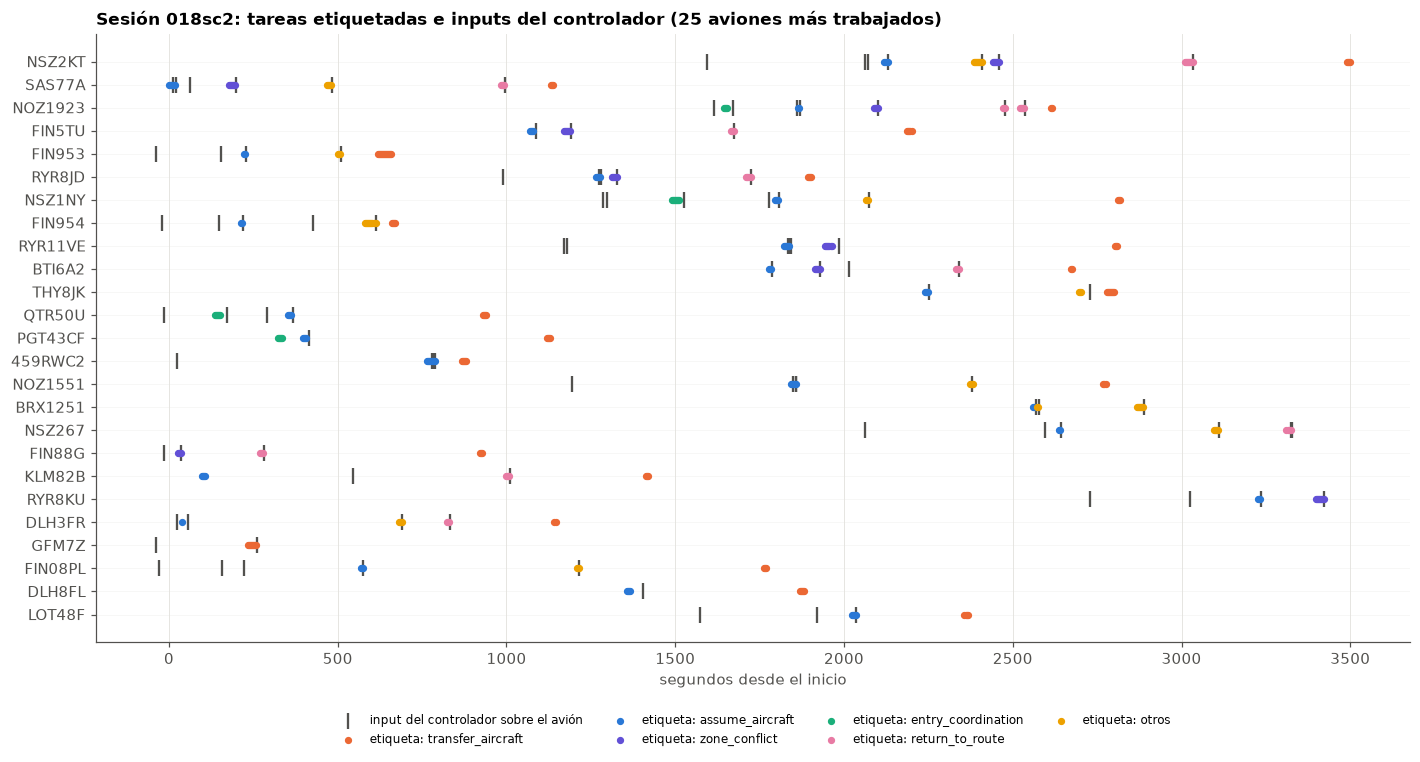

In [16]:
S = "018sc2"
g = lab[lab.session == S]
p = pos[pos.session == S]
ev = g[g.a_since_flight < 3600].assign(ev=lambda x: (x.t - x.a_since_flight).round()).drop_duplicates(["cs", "ev"])
acs = p.cs.value_counts().index[:25]
yy = {a: i for i, a in enumerate(acs)}
fig, ax = plt.subplots(figsize=(13, 7))
e = ev[ev.cs.isin(acs)]
ax.scatter(e.ev - g.t.min(), e.cs.map(yy), marker="|", s=120, color=C["ink2"], lw=1.5, label="input del controlador sobre el avión")
pp = p[p.cs.isin(acs)]
for ty, c in zip(["transfer_aircraft", "assume_aircraft", "zone_conflict", "entry_coordination", "return_to_route"],
                 [C["orange"], C["blue"], C["violet"], C["aqua"], C["magenta"]]):
    q = pp[pp.type == ty]
    ax.scatter(q.t - g.t.min(), q.cs.map(yy), s=14, color=c, label=f"etiqueta: {ty}", zorder=3)
q = pp[~pp.type.isin(["transfer_aircraft", "assume_aircraft", "zone_conflict", "entry_coordination", "return_to_route"])]
ax.scatter(q.t - g.t.min(), q.cs.map(yy), s=14, color=C["yellow"], label="etiqueta: otros", zorder=3)
ax.set_yticks(range(len(acs)), acs); ax.invert_yaxis()
ax.set(title=f"Sesión {S}: tareas etiquetadas e inputs del controlador (25 aviones más trabajados)", xlabel="segundos desde el inicio")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4, fontsize=8); ax.grid(axis="y", alpha=0.3)
plt.tight_layout()

**Lectura:** los episodios etiquetados suelen **terminar con un input** del controlador sobre ese avión (el clic de assume, transfer, nivel…). Es decir, el input llega *después* de que empiece a trabajar en la tarea. Esto motiva la siguiente sección.

## 8 · Inputs del controlador: pasado vs futuro

`a_since_flight` dice cuánto hace del último input sobre el avión. A partir de él reconstruimos los instantes de cada input (`t - a_since_flight`) y, mirando snapshots **posteriores** de la misma sesión, el tiempo hasta el **siguiente** input sobre el avión (`f_next_input`, lo que hace el baseline).

⚠️ Esto usa información del futuro de la sesión. Con el fichero de test completo es calculable (no usa etiquetas), pero **no sería posible en tiempo real** en un asistente operativo. Conviene confirmar con la organización que está permitido y, en cualquier caso, contarlo al jurado.

Rango del avión elegido entre las tareas de la muestra (1 = el más reciente / el más próximo):
     pasado (último input)  futuro (siguiente input)
1.0                   14.4                      48.2
2.0                    2.8                       1.8
3.0                    2.9                       2.7
4.0                    3.4                       1.9
5.0                    3.6                       1.2

Sin siguiente input conocido (NaN): 33.8% de las respuestas


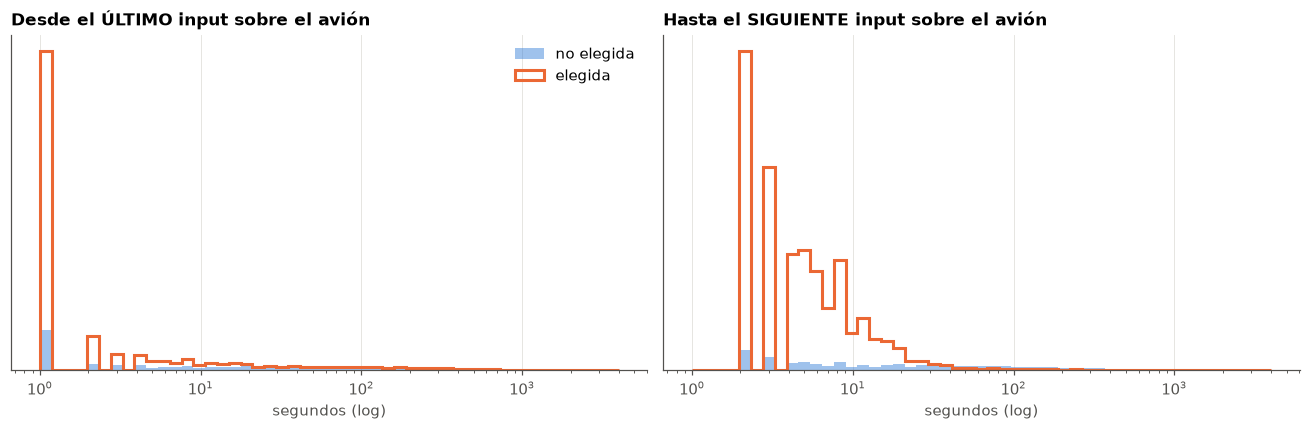

In [17]:
def add_next_input(d):
    d = d.copy()
    d["ev"] = np.where(d.a_since_flight < 3600, d.t - d.a_since_flight, np.nan)
    nxt = np.full(len(d), np.nan)
    for _, g in d.groupby("session"):
        evs = g.dropna(subset=["ev"]).groupby("cs").ev.apply(lambda s: np.unique(np.round(s.values)))
        for i, cs, t in zip(g.index, g.cs.values, g.t.values):
            e = evs.get(cs)
            if e is not None:
                j = np.searchsorted(e, t + 1.5)
                if j < len(e): nxt[i] = e[j] - t
    d["f_next_input"] = nxt
    d["f_next_input_rk"] = d.groupby("sample_id").f_next_input.rank(method="min")
    d["a_since_flight_rk"] = d.groupby("sample_id").a_since_flight.rank(method="min")
    return d

d = add_next_input(d)
lab = d[d.split != "test"]; pos = lab[lab.target_index == 1]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
b = np.logspace(0, 3.6, 50)
for (col, ttl), a in zip([("a_since_flight", "Desde el ÚLTIMO input sobre el avión"), ("f_next_input", "Hasta el SIGUIENTE input sobre el avión")], ax):
    a.hist(lab[lab.target_index == 0][col].clip(1, 3600), b, density=True, color=OTHER, alpha=0.45, label="no elegida")
    a.hist(pos[col].clip(1, 3600), b, density=True, histtype="step", lw=2, color=TARGET, label="elegida")
    a.set(xscale="log", title=ttl, xlabel="segundos (log)", yticks=[])
ax[0].legend(); plt.tight_layout()

ranks = pd.DataFrame({"pasado (último input)": pos.a_since_flight_rk.value_counts() / len(pos),
                      "futuro (siguiente input)": pos.f_next_input_rk.value_counts() / len(pos)}).loc[1:5]
print("Rango del avión elegido entre las tareas de la muestra (1 = el más reciente / el más próximo):")
print((ranks * 100).round(1).to_string())
print(f"\nSin siguiente input conocido (NaN): {pos.f_next_input.isna().mean():.1%} de las respuestas")

**Lectura:** es la señal más fuerte del dataset con diferencia: en ~48 % de las muestras la tarea elegida pertenece al avión que recibe el **próximo** input (mediana ~11 s después), frente a ~14 % para el último input. Tiene sentido: el controlador «trabaja» en una tarea y la cierra con un clic. Esto explica el salto 0.35 → 0.83 del baseline.

Dentro del avión correcto aún hay que elegir **qué tarea** (p. ej. assume vs entry_coordination). Ahí el tipo del siguiente input (que no tenemos directamente, solo `a_last_*` en el snapshot posterior) podría ayudar mucho: si el próximo input es un `assume_control`, la tarea era `assume_aircraft`.

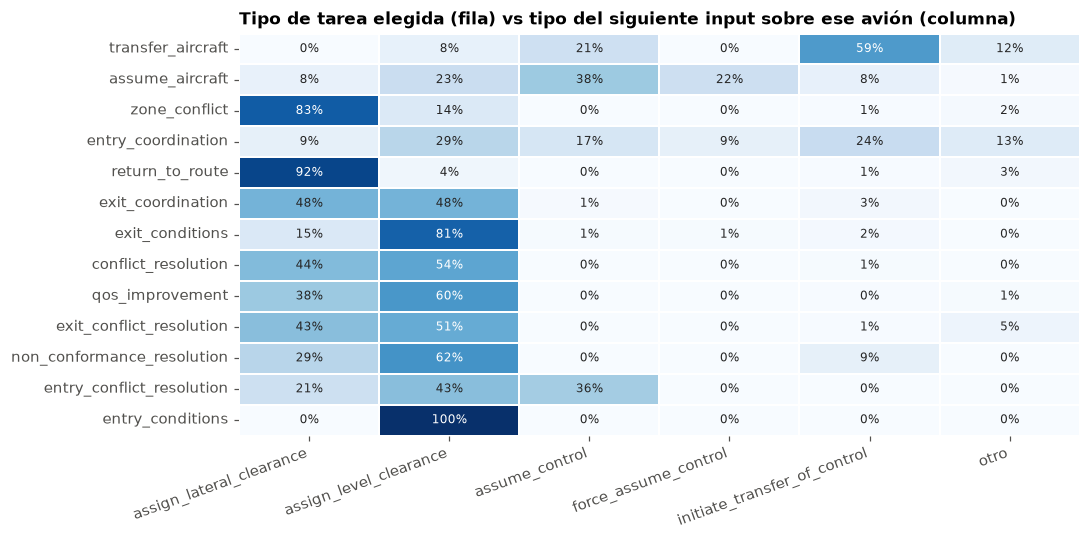

In [18]:
# ¿Qué input llega después? Leemos a_last_* en el primer snapshot posterior al input
acts = ["a_last_assume_control", "a_last_force_assume_control", "a_last_assign_level_clearance",
        "a_last_assign_lateral_clearance", "a_last_initiate_transfer_of_control"]
k = lab[lab.a_since_flight < 3600].assign(ev=lambda x: (x.t - x.a_since_flight).round())
first = k.sort_values("t").drop_duplicates(["session", "cs", "ev"])[["session", "cs", "ev"] + acts]
first["next_act"] = first[acts].idxmax(axis=1).where(first[acts].max(axis=1) == 1, "otro").str.replace("a_last_", "")
q = pos[pos.f_next_input.notna()].assign(ev=lambda x: (x.t + x.f_next_input).round())
q = q.merge(first[["session", "cs", "ev", "next_act"]], on=["session", "cs", "ev"], how="left")
ct = pd.crosstab(q.type, q.next_act, normalize="index")
ct = ct.loc[tt.index.intersection(ct.index)]
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(ct, annot=True, fmt=".0%", cmap="Blues", cbar=False, linewidths=1, linecolor="white", ax=ax, annot_kws=dict(size=8))
ax.set(title="Tipo de tarea elegida (fila) vs tipo del siguiente input sobre ese avión (columna)", xlabel="", ylabel="")
plt.setp(ax.get_xticklabels(), rotation=20, ha="right"); plt.tight_layout()

**Lectura:** el tipo del siguiente input está muy asociado al tipo de tarea: `zone_conflict`/`return_to_route` → clearance lateral (83–92 %), `exit_conditions` → nivel (81 %), `transfer` → `initiate_transfer` (59 %), `assume` → (force_)assume_control (60 %). Feature derivada prometedora: `next_act` del avión cruzado con el tipo de la tarea — ayuda a separar las tareas **de un mismo avión**, que es justo donde el resto de columnas no discrimina.

Ojo: el último input sobre un avión que sale del sector (el transfer) a menudo **no se ve**, porque tras transferirlo el avión deja la lista y ningún snapshot posterior lo registra (se aprecia en la línea temporal: muchos transfers sin marca). Eso motiva la sección siguiente.

### 8b · La tarea desaparece de la lista

Si el controlador **completa** la tarea, AWARE la quita de su lista. Medimos, para cada fila, cuántos segundos faltan hasta la **última vez que esa tarea (`task_name`) aparece** en la sesión, y lo mismo por avión. También es información futura (mismas reservas que `f_next_input`).

Matiz: solo hay snapshots en momentos etiquetados, así que «última aparición» está limitada por la cobertura de muestras; en test el mecanismo es el mismo, así que la feature es igual de calculable.

top-3 ordenando solo por f_task_end    (menor primero): 0.561
top-3 ordenando solo por f_cs_end      (menor primero): 0.286
top-3 ordenando solo por f_next_input  (menor primero): 0.458


La elegida desaparece en ≤15 s: 57.7%  · resto de filas: 5.2%


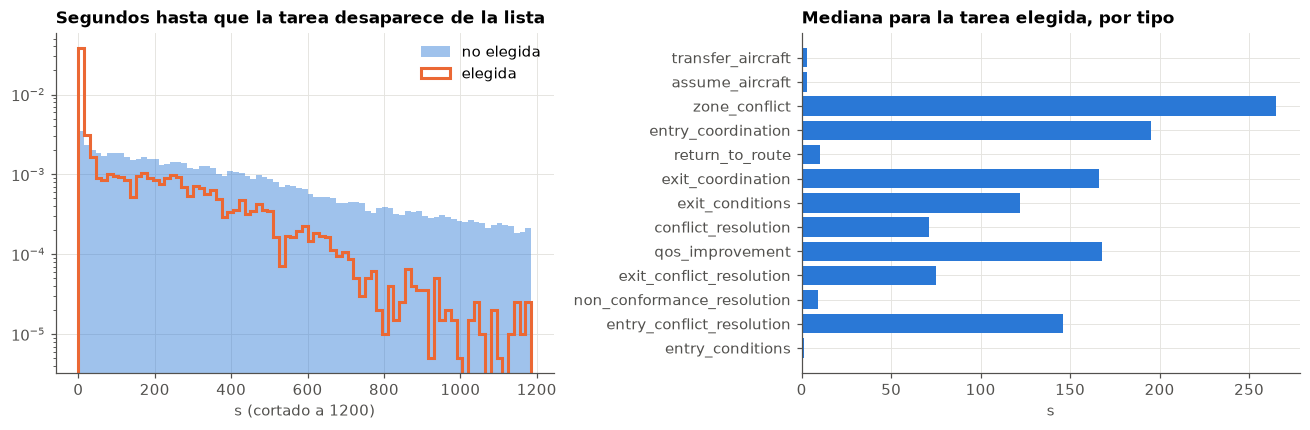

In [19]:
d["f_task_end"] = d.groupby(["session", "task_name"]).t.transform("max") - d.t     # s hasta la última aparición de la tarea
d["f_cs_end"] = d.groupby(["session", "cs"]).t.transform("max") - d.t             # ... del avión
d["f_task_end_rk"] = d.groupby("sample_id").f_task_end.rank(method="min")
lab = d[d.split != "test"]; pos = lab[lab.target_index == 1]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
b = np.arange(0, 1200, 15)
ax[0].hist(lab[lab.target_index == 0].f_task_end.clip(upper=1199), b, density=True, color=OTHER, alpha=0.45, label="no elegida")
ax[0].hist(pos.f_task_end.clip(upper=1199), b, density=True, histtype="step", lw=2, color=TARGET, label="elegida")
ax[0].set(title="Segundos hasta que la tarea desaparece de la lista", xlabel="s (cortado a 1200)", yticks=[], yscale="log"); ax[0].legend()
m = pos.groupby("type").f_task_end.median().reindex(tt.index).dropna()
ax[1].barh(m.index[::-1], m.values[::-1], color=OTHER); ax[1].set(title="Mediana para la tarea elegida, por tipo", xlabel="s")
plt.tight_layout()
for c in ["f_task_end", "f_cs_end", "f_next_input"]:
    print(f"top-3 ordenando solo por {c:13s} (menor primero): {hit3(lab, -lab[c]):.3f}")
print(f"La elegida desaparece en ≤15 s: {(pos.f_task_end <= 15).mean():.1%}  · resto de filas: {(lab[lab.target_index == 0].f_task_end <= 15).mean():.1%}")

**Lectura:** es la feature univariante más fuerte del dataset. `assume`, `transfer`, `return_to_route` y `non_conformance` se **cierran** al trabajarlas (desaparecen en segundos); `zone_conflict`, coordinaciones o conflictos persisten aunque se trabajen. Combinada con el siguiente input y el tipo, debería empujar el ranker por encima del baseline.

## 9 · Mismo escenario, distintos controladores

Los escenarios repiten tráfico. Si alineamos el tiempo de escenario, podemos construir un *prior colectivo*: «a este minuto del escenario, ¿con qué avión estaban los otros controladores?». No memoriza a un controlador concreto sino el consenso; es legítimo para test porque solo usa etiquetas de train/val.

Primero comprobamos que el reloj del escenario está alineado entre sesiones: el instante en que cada avión aparece por primera vez debería coincidir.

Desfase mediano de cada sesión respecto al consenso (s):
count     42.0
mean      -3.5
std       17.5
min     -103.0
25%        0.0
50%        0.0
75%        0.0
max       10.0


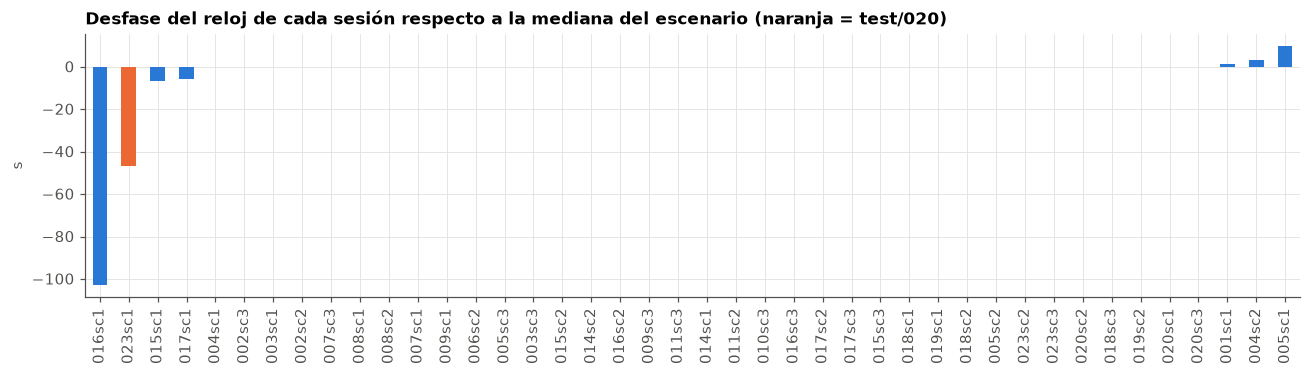

In [20]:
fa = d.groupby(["scenario", "session", "cs"]).t_scn.min().reset_index()
spread = fa.groupby(["scenario", "cs"]).t_scn.agg(["std", "count"]).query("count >= 5")
off = fa.merge(fa.groupby(["scenario", "cs"]).t_scn.median().rename("med"), on=["scenario", "cs"])
off["delta"] = off.t_scn - off.med
sess_off = off.groupby("session").delta.median()
print("Desfase mediano de cada sesión respecto al consenso (s):"); print(sess_off.describe().round(1).to_string())
fig, ax = plt.subplots(figsize=(12, 3.5))
sess_off.sort_values().plot.bar(ax=ax, color=[C["orange"] if s[:3] in ("020", "023") else OTHER for s in sess_off.sort_values().index])
ax.set(title="Desfase del reloj de cada sesión respecto a la mediana del escenario (naranja = test/020)", ylabel="s", xlabel="")
plt.tight_layout()

In [21]:
# Prior colectivo leave-one-ATCO-out: para cada fila, fracción de muestras de OTROS controladores del mismo escenario,
# en ±W s de tiempo de escenario (corregido por desfase), cuya respuesta era ese mismo avión / esa misma tarea.
W = 30
d["t_al"] = d.t_scn - d.session.map(sess_off).fillna(0)
P = d[d.target_index == 1][["scenario", "atco", "t_al", "cs", "task_name"]]

def collective_prior(rows, key):
    out = pd.Series(0.0, index=rows.index)
    for (scn, atco), g in rows.groupby(["scenario", "atco"]):
        o = P[(P.scenario == scn) & (P.atco != atco)].sort_values("t_al")
        ot = o.t_al.values; ok = o[key].values
        lo = np.searchsorted(ot, g.t_al.values - W); hi = np.searchsorted(ot, g.t_al.values + W)
        out[g.index] = [(ok[a:b] == k).mean() if b > a else 0 for a, b, k in zip(lo, hi, g[key].values)]
    return out.values

lab = d[d.split != "test"].copy()
lab["cp_cs"] = collective_prior(lab, "cs")
lab["cp_task"] = collective_prior(lab, "task_name")
print(f"top-3 solo con prior colectivo por avión : {hit3(lab, lab.cp_cs + 1e-3 * lab.task_index.map(prior).fillna(0)):.3f}")
print(f"top-3 solo con prior colectivo por tarea : {hit3(lab, lab.cp_task):.3f}")
print(f"top-3 prior tipo × cercanía (referencia) : {uni.loc['prior tipo × cercanía', 'mejor']:.3f}")

top-3 solo con prior colectivo por avión : 0.263
top-3 solo con prior colectivo por tarea : 0.398
top-3 prior tipo × cercanía (referencia) : 0.501


**Lectura:** el consenso de otros controladores sobre el mismo tráfico es una señal razonable por sí sola y es **complementaria** a las features del snapshot (captura «qué está pasando en este momento del escenario»). Como feature de un ranker debe calcularse siempre *leave-one-atco-out* para no filtrar la etiqueta.

## 10 · Ablación rápida del baseline (LightGBM LambdaRank)

Mismo modelo que `src/baseline_ranker.py` (algo más ligero), CV GroupKFold por controlador, con distintos conjuntos de features. Así vemos de dónde viene el 0.83.

In [22]:
import lightgbm as lgb
from sklearn.model_selection import GroupKFold

base_feats = [c for c in num] + ["task_index"]
lab = lab.sort_values(["sample_id", "row_index"]).reset_index(drop=True)
lab["a_since_flight_rk"] = lab.groupby("sample_id").a_since_flight.rank(method="min")

def cv(feats, n_estimators=250):
    hits, oof = [], np.zeros(len(lab))
    for a, b in GroupKFold(5).split(lab, groups=lab.atco):
        A, B = lab.iloc[a], lab.iloc[b]
        m = lgb.LGBMRanker(objective="lambdarank", n_estimators=n_estimators, learning_rate=0.05, num_leaves=31,
                           min_child_samples=50, subsample=0.8, subsample_freq=1, colsample_bytree=0.7,
                           lambdarank_truncation_level=5, verbose=-1)
        m.fit(A[feats], A.target_index, group=A.groupby("sample_id", sort=False).size().values, categorical_feature=["task_index"])
        oof[b] = m.predict(B[feats])
    return hit3(lab, oof), oof, m

configs = {
    "snapshot (sin futuro)": base_feats + ["a_since_flight_rk"],
    "+ prior colectivo": base_feats + ["a_since_flight_rk", "cp_cs", "cp_task"],
    "+ siguiente input (baseline)": base_feats + ["f_next_input", "f_next_input_rk"],
    "+ siguiente input + prior colectivo": base_feats + ["f_next_input", "f_next_input_rk", "cp_cs", "cp_task"],
    "+ siguiente input + desaparición tarea": base_feats + ["f_next_input", "f_next_input_rk", "f_task_end", "f_cs_end", "f_task_end_rk"],
}
abl, models, oofs = {}, {}, {}
for k, f in configs.items():
    abl[k], oofs[k], models[k] = cv(f)
    print(f"{k:40s} CV top-3 = {abl[k]:.4f}")

snapshot (sin futuro)                    CV top-3 = 0.6516


+ prior colectivo                        CV top-3 = 0.6647


+ siguiente input (baseline)             CV top-3 = 0.8332


+ siguiente input + prior colectivo      CV top-3 = 0.8304


+ siguiente input + desaparición tarea   CV top-3 = 0.8918


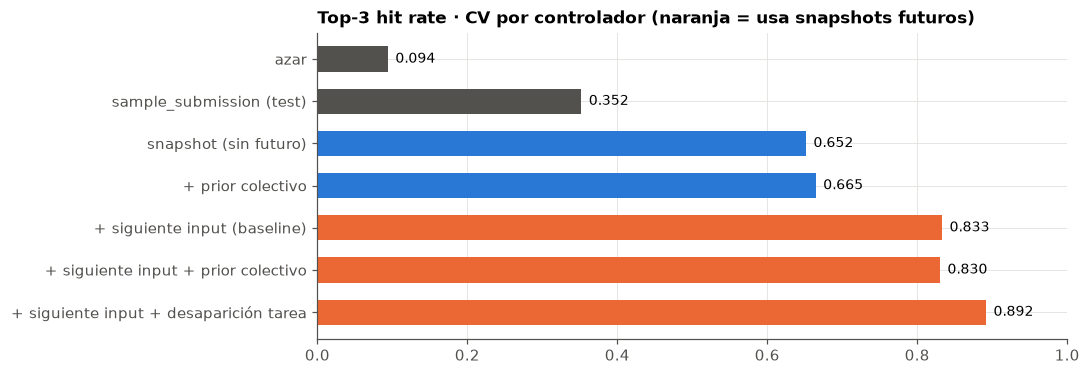

In [23]:
ref = {"azar": 0.094, "sample_submission (test)": 0.352}
s = pd.Series({**ref, **abl})
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.barh(s.index[::-1], s.values[::-1], color=[C["ink2"] if k in ref else (TARGET if "siguiente" in k else OTHER) for k in s.index[::-1]], height=0.6)
for i, v in enumerate(s.values[::-1]): ax.text(v + 0.01, i, f"{v:.3f}", va="center", fontsize=9)
ax.set(xlim=(0, 1), title="Top-3 hit rate · CV por controlador (naranja = usa snapshots futuros)"); plt.tight_layout()

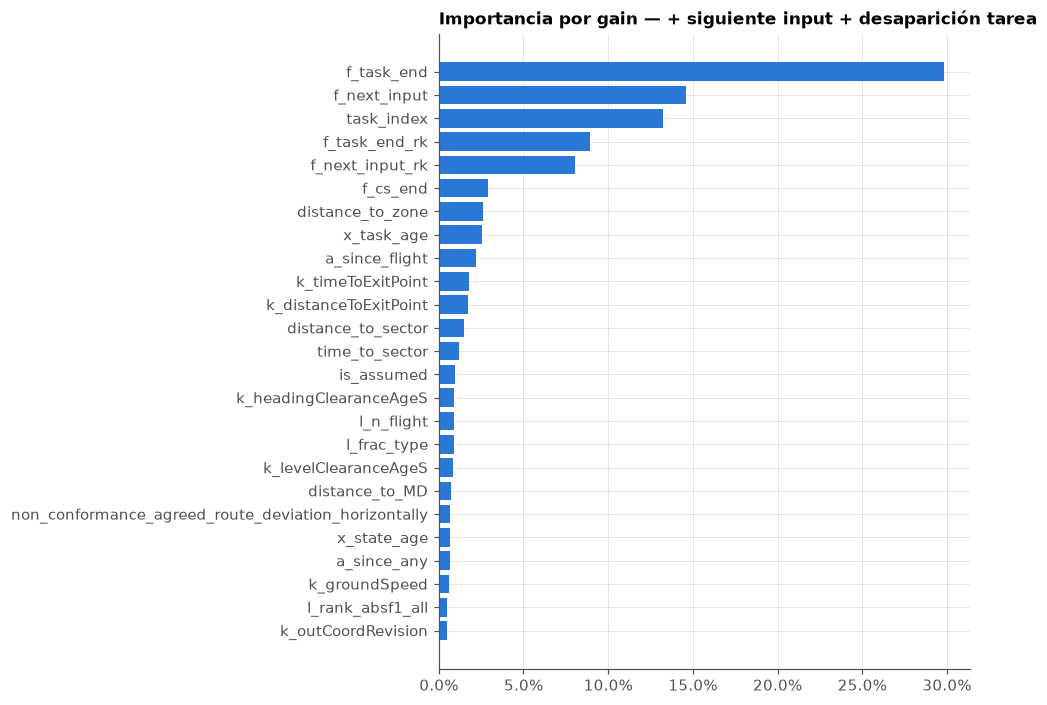

In [24]:
# Importancia (gain) del modelo completo, último fold
k = "+ siguiente input + desaparición tarea"
imp = pd.Series(models[k].booster_.feature_importance("gain"), index=configs[k]).sort_values(ascending=False).head(25)
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(imp.index[::-1], imp.values[::-1] / imp.sum(), color=OTHER)
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1)); ax.set_title(f"Importancia por gain — {k}"); plt.tight_layout()

Dispersión entre controladores: min 0.754 · max 0.952 · std 0.056


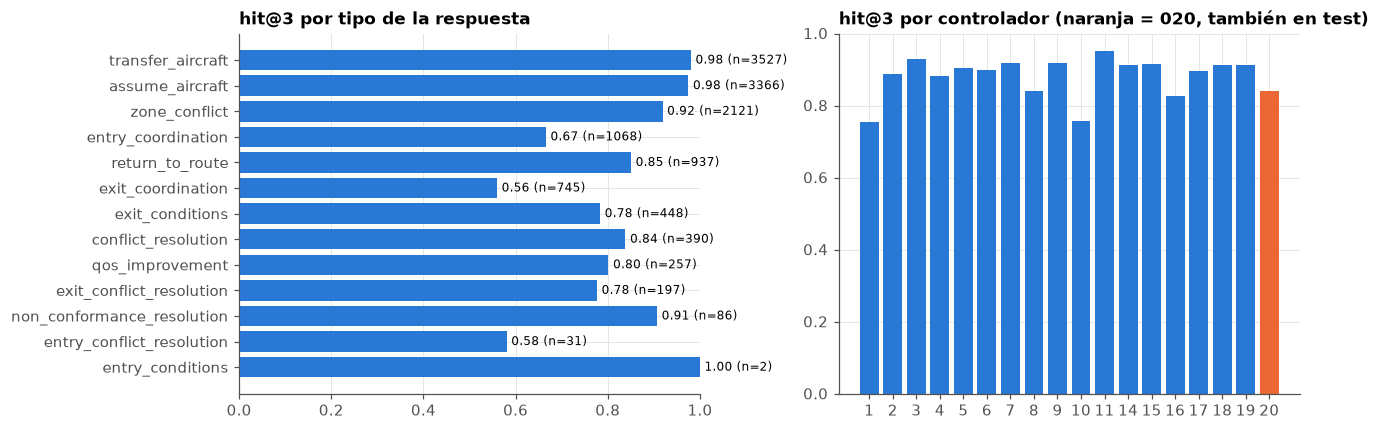

In [25]:
# ¿Dónde falla el mejor modelo? hit-rate por tipo de la respuesta y por controlador
lab["oof"] = oofs[k]
lab["rk"] = lab.groupby("sample_id").oof.rank(ascending=False, method="first")
pp = lab[lab.target_index == 1]
by_type = pp.groupby("type").rk.apply(lambda r: (r <= 3).mean()).to_frame("hit@3").join(pp.type.value_counts().rename("n"))
by_atco = pp.groupby("atco").rk.apply(lambda r: (r <= 3).mean())
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
bt = by_type.sort_values("n", ascending=False)
ax[0].barh(bt.index[::-1], bt["hit@3"][::-1], color=OTHER); ax[0].set(title="hit@3 por tipo de la respuesta", xlim=(0, 1))
for i, (v, n) in enumerate(zip(bt["hit@3"][::-1], bt.n[::-1])): ax[0].text(v + 0.01, i, f"{v:.2f} (n={n})", va="center", fontsize=8)
ax[1].bar(by_atco.index.astype(str), by_atco.values, color=[TARGET if a == 20 else OTHER for a in by_atco.index])
ax[1].set(title="hit@3 por controlador (naranja = 020, también en test)", ylim=(0, 1)); plt.tight_layout()
print(f"Dispersión entre controladores: min {by_atco.min():.3f} · max {by_atco.max():.3f} · std {by_atco.std():.3f}")

## 11 · Conclusiones y posibles enfoques

**Lo que hemos aprendido**
1. Es un problema de *ranking* intra-snapshot: lo que importa es comparar tareas de la misma muestra, no valores absolutos. `row_index` no tiene información (la lista va por orden alfabético de callsign).
2. **El tipo de tarea** fija mucho (transfer/assume = 50 % de respuestas) y **la cercanía al borde, por tipo**, decide el avión dentro del tipo (assume antes de entrar, transfer antes de salir). Con solo eso: ~0.35.
3. **Los inputs del controlador** son la señal dominante. El *siguiente* input sobre un avión delata en qué avión estaba trabajando (~48 % rango 1). El baseline salta a ~0.83 casi solo por esto. Usa información futura de la sesión → validar que está permitido y contarlo al jurado.
4. **Temporalidad**: ~64 % de muestras repiten la tarea anterior; ~4.7k episodios efectivos.
5. **Ruido y estilo humano**: alta variación entre controladores; el techo no es 100 %.
6. Los NaN son estructurales (no asumido / sin conflicto / sin zona): dejarlos como NaN.

**Enfoques a probar (ordenados por retorno esperado)**
- **Features del siguiente input enriquecidas**: tipo de la siguiente acción (`next_act`) cruzado con el tipo de tarea (resuelve assume vs entry_coordination), tiempo al 2º siguiente input, nº de inputs futuros en ±30 s, rango por avión.
- **Post-proceso temporal**: suavizar scores entre snapshots consecutivos de la misma sesión (media móvil / HMM con probabilidad de «seguir en la misma tarea» ≈ 0.64), sin mirar etiquetas.
- **Features de contexto temporal sin futuro** (robustas si el uso del futuro no se permite): deltas de cada feature respecto al snapshot anterior, «tarea recién aparecida», cambios de estado (`x_transfer_in` que pasa a 1…).
- **Prior colectivo leave-one-atco-out** por escenario y tiempo alineado.
- **Modelado jerárquico**: elegir avión (ranker sobre aviones) y después tarea dentro del avión (clasificador pequeño con tipo + `next_act` + `x_task_age`).
- **Robustez**: CV por controlador, ensamblado de semillas/modelos (LightGBM lambdarank + CatBoost YetiRank + XGBoost), regularizar; elegir por CV y no por el LB público (solo 1 controlador, 915 muestras).
- La validación oficial incluye 020sc1: entrenar el modelo final con train + validation.